In [1]:
# Settings 

from pathlib import Path
from datetime import datetime
from getpass import getpass
import os

# Main folders 
WORK = Path("/workspace")   

# Check BEFORE creating anything: if the volume isn't attached, stop here
if not WORK.exists():
    raise FileNotFoundError("/workspace not found - is the RunPod volume attached?")

SETUP      = WORK / "AMI-diarization-setup"      
AUDIO_ROOT = SETUP / "pyannote" / "amicorpus"   
ANNOT_DIR  = WORK / "ami_annotations"            
RESULTS    = WORK / "results" / "data"
FIGURES    = WORK / "results" / "figures"
LOG_DIR    = WORK / "logs"
ENV        = WORK / "envs" / "pyannote21"

# Data choices 
SPLITS            = ["train", "dev", "test"]   
EVAL_SPLIT        = "test"                     
REFERENCE_SET     = "only_words"               
DOWNLOAD_FARFIELD = False                     

# Reproducibility
SEED   = 42
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S") 

# Hugging Face token 

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    HF_TOKEN = getpass("Paste your Hugging Face token: ")
    os.environ["HF_TOKEN"] = HF_TOKEN   

if not HF_TOKEN:
    raise ValueError("No Hugging Face token given - the pyannote model download will fail.")

# Download sources 
AMI_MIRROR      = "https://groups.inf.ed.ac.uk/ami/AMICorpusMirror/amicorpus"
ANNOTATIONS_URL = "https://groups.inf.ed.ac.uk/ami/AMICorpusAnnotations/ami_public_manual_1.6.2.zip"
SETUP_REPO      = "https://github.com/pyannote/AMI-diarization-setup.git"

# Create output folders
for folder in [RESULTS, FIGURES, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Working folder:", WORK)
print("Run ID:", RUN_ID, "(UTC) | eval split:", EVAL_SPLIT, "| reference:", REFERENCE_SET)
print("HF token loaded ")

Paste your Hugging Face token:  ········


Working folder: /workspace
Run ID: 20261020_205159 (UTC) | eval split: test | reference: only_words
HF token loaded 


In [2]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Check the Hugging Face token
import json
import urllib.request
import urllib.error

def hf_request(url):
    """Send a request to Hugging Face with the token; return (status code, body)."""
    req = urllib.request.Request(url, headers={"Authorization": f"Bearer {HF_TOKEN}"})
    try:
        with urllib.request.urlopen(req, timeout=20) as resp:
            return resp.status, resp.read()
    except urllib.error.HTTPError as e:
        return e.code, b""

# 1) Is the token valid?
status, body = hf_request("https://huggingface.co/api/whoami-v2")
if status == 200:
    print("Token valid Logged in as:", json.loads(body)["name"])
else:
    raise ValueError(f"Token rejected (HTTP {status}) - create a new one at huggingface.co/settings/tokens")

# 2) Can this account download the gated pyannote models?
for repo in ["pyannote/speaker-diarization", "pyannote/segmentation"]:
    status, _ = hf_request(f"https://huggingface.co/{repo}/resolve/main/config.yaml")
    if status == 200:
        print(f"{repo}: access granted")
    elif status in (401, 403):
        print(f"{repo}: NO ACCESS -> open huggingface.co/{repo} and accept the conditions")
    else:
        print(f"{repo}: unexpected HTTP {status} - tell Claude")

Token valid Logged in as: pipelix
pyannote/speaker-diarization: access granted
pyannote/segmentation: access granted


In [4]:
# Official AMI diarization setup 

import subprocess, json

if not (SETUP / "lists").exists():
    print("Downloading the AMI diarization setup from GitHub ...")
    subprocess.run(["git", "clone", "--quiet", SETUP_REPO, str(SETUP)], check=True)
else:
    print("Already downloaded - skipping.")

# Record the exact repo version (reproducibility)
commit = subprocess.run(["git", "-C", str(SETUP), "rev-parse", "HEAD"],
                        capture_output=True, text=True, check=True).stdout.strip()
print("Setup repo commit:", commit)

# Read the official split lists
meetings = {}
for split in SPLITS:
    list_file = SETUP / "lists" / f"{split}.meetings.txt"
    meetings[split] = list_file.read_text().split()
    print(f"{split:5s}: {len(meetings[split]):3d} meetings   e.g. {meetings[split][:3]}")
print("Total:", sum(len(m) for m in meetings.values()), "meetings")

# Sanity check 1: expected split sizes (Full-corpus-ASR partition)
expected = {"train": 136, "dev": 18, "test": 16}
for split in SPLITS:
    assert len(meetings[split]) == expected[split], f"{split} has wrong size!"

# Sanity check 2: no meeting appears in more than one split
all_ids = [m for split in SPLITS for m in meetings[split]]
assert len(all_ids) == len(set(all_ids)), "A meeting appears in two splits!"

# Sanity check 3: every eval meeting has a reference RTTM
ref_dir = SETUP / REFERENCE_SET
missing = [m for m in meetings[EVAL_SPLIT] if not list(ref_dir.rglob(f"{m}.rttm"))]
assert not missing, f"No reference RTTM for: {missing}"
print(f"All {len(meetings[EVAL_SPLIT])} {EVAL_SPLIT} meetings have {REFERENCE_SET} references ✓")

# Save split info + commit with this run's logs
with open(LOG_DIR / f"splits_{RUN_ID}.json", "w") as f:
    json.dump({"setup_commit": commit, "meetings": meetings}, f, indent=2)

Already downloaded - skipping.
Setup repo commit: 67c2d539286e89f68952d5dcf83912bd9f01dfae
train: 136 meetings   e.g. ['IS1000a', 'IS1000b', 'IS1000c']
dev  :  18 meetings   e.g. ['IS1008a', 'IS1008b', 'IS1008c']
test :  16 meetings   e.g. ['IS1009a', 'IS1009b', 'IS1009c']
Total: 170 meetings
All 16 test meetings have only_words references ✓


In [5]:
# Helper functions for safe downloading

import urllib.request
import logging
import shutil
import time

# Log file named with this run's RUN_ID 
log_file = LOG_DIR / f"download_{RUN_ID}.log"
logging.basicConfig(filename=log_file, level=logging.INFO,
                    format="%(asctime)s %(levelname)s %(message)s", force=True)


def remote_size(url):
    
    request = urllib.request.Request(url, method="HEAD")
    with urllib.request.urlopen(request, timeout=60) as response:
        size = response.headers.get("Content-Length")
        return int(size) if size else None


def download(url, destination, retries=3):
    
    destination.parent.mkdir(parents=True, exist_ok=True)  
    expected = remote_size(url)

    
    if destination.exists() and (expected is None or destination.stat().st_size == expected):
        logging.info(f"SKIP {destination.name} (already complete)")
        return "skipped"

    temporary = destination.with_name(destination.name + ".part")

    for attempt in range(1, retries + 1):
        try:
            # Download to a temporary file first 
            with urllib.request.urlopen(url, timeout=60) as response, open(temporary, "wb") as out:
                shutil.copyfileobj(response, out)

            # Check the size matches before accepting the file
            got = temporary.stat().st_size
            if expected is not None and got != expected:
                raise IOError(f"size mismatch: got {got}, expected {expected}")

            temporary.replace(destination)  
            logging.info(f"OK   {destination.name} ({got / 1e6:.1f} MB)")
            return "downloaded"

        except Exception as error:
            temporary.unlink(missing_ok=True)   
            logging.warning(f"FAIL {destination.name} attempt {attempt}/{retries}: {error}")
            if attempt == retries:
                raise                           
            time.sleep(5 * attempt)            


print("Helpers ready. Log file:", log_file)

Helpers ready. Log file: /workspace/logs/download_20261020_205159.log


In [8]:
# Download the audio for all meetings

import shutil
from concurrent.futures import ThreadPoolExecutor


free_gb = shutil.disk_usage(WORK).free / 1e9
print("Free space:", round(free_gb, 1), "GB")
if free_gb < 15:
    raise RuntimeError("Not enough disk space!")

# Make one list of all meetings, test meetings first 
all_meetings = meetings["test"] + meetings["dev"] + meetings["train"]
print("Meetings to download:", len(all_meetings))


# A small function that downloads ONE meeting 
def get_meeting(meeting):
    url  = f"{AMI_MIRROR}/{meeting}/audio/{meeting}.Mix-Headset.wav"
    dest = AUDIO_ROOT / meeting / "audio" / f"{meeting}.Mix-Headset.wav"
    try:
        result = download(url, dest)       
    except Exception as error:
        result = "FAILED"
    print(meeting, result)
    return result


# Download 4 meetings at the same time 
with ThreadPoolExecutor(max_workers=2) as pool:
    results = list(pool.map(get_meeting, all_meetings))

print()
print("Downloaded:", results.count("downloaded"))
print("Skipped (already had it):", results.count("skipped"))
print("Failed:", results.count("FAILED"))

# Final check is every file really exist
missing = []
for meeting in all_meetings:
    file = AUDIO_ROOT / meeting / "audio" / f"{meeting}.Mix-Headset.wav"
    if not file.exists():
        missing.append(meeting)

if missing:
    print("Missing:", missing)
    raise RuntimeError("Some files are missing - just run this cell again.")
else:
    print("All", len(all_meetings), "meetings downloaded ✓")

Free space: 50.0 GB
Meetings to download: 170
IS1009b skipped
IS1009a skipped
IS1009d skipped
IS1009c skipped
ES2004a skipped
ES2004c skipped
ES2004d skipped
TS3003a skipped
ES2004b skipped
TS3003b skipped
TS3003c skipped
TS3003d skipped
EN2002a skipped
EN2002b skipped
EN2002c skipped
EN2002d skipped
IS1008a skipped
IS1008b skipped
IS1008c skipped
IS1008d skipped
ES2011a skipped
ES2011b skipped
ES2011c skipped
ES2011d skipped
TS3004b skipped
TS3004c skipped
TS3004d skipped
IB4001 skipped
IB4002 skipped
IB4003 skipped
IB4004 skipped
IB4010 skipped
TS3004a skipped
IB4011 skipped
IS1000b skipped
IS1000a skipped
IS1000c skipped
IS1000d skipped
IS1001b skipped
IS1001c skipped
IS1001a skipped
IS1001d skipped
IS1002b skipped
IS1002c skipped
IS1002d skipped
IS1003a skipped
IS1003b skipped
IS1003c skipped
IS1004a skipped
IS1003d skipped
IS1004b skipped
IS1004c skipped
IS1004d skipped
IS1005a skipped
IS1005b skipped
IS1005c skipped
IS1006a skipped
IS1006c skipped
IS1006d skipped
IS1007a skipped


## Download the AMI manual annotations


In [9]:
# AMI manual annotations v1.6.2

import zipfile
import hashlib

zip_path = ANNOT_DIR / "ami_public_manual_1.6.2.zip"
status = download(ANNOTATIONS_URL, zip_path)
print("Annotations zip:", status)

sha256 = hashlib.sha256(zip_path.read_bytes()).hexdigest()
print("SHA-256:", sha256)
logging.info(f"annotations zip sha256 {sha256}")


marker = ANNOT_DIR / ".unzipped"
if not marker.exists():
    with zipfile.ZipFile(zip_path) as archive:
        broken = archive.testzip()              
        if broken is not None:
            raise IOError(f"Corrupted file in zip: {broken} - delete the zip and re-run")
        archive.extractall(ANNOT_DIR)
    marker.touch()


folders = sorted(p.name for p in ANNOT_DIR.iterdir() if p.is_dir())
print("Folders:", folders)


words_dir = next(ANNOT_DIR.rglob("words"), None)
assert words_dir is not None, "No 'words' folder found in the annotations!"
n_word_files = len(list(words_dir.glob("*.words.xml")))
print(f"Word transcript files: {n_word_files}  ({words_dir})")

Annotations zip: downloaded
SHA-256: b56e5babb2496b8795deeeda7e71178d7fbc9963f94276cf2a3f4b56ebbc9f9d
Folders: ['abstractive', 'argumentation', 'configuration', 'corpusResources', 'corpusdoc', 'decision', 'dialogueActs', 'disfluency', 'extractive', 'focus', 'handGesture', 'headGesture', 'movement', 'namedEntities', 'ontologies', 'participantRoles', 'participantSummaries', 'segments', 'topics', 'words', 'youUsages']
Word transcript files: 687  (/workspace/ami_annotations/words)


## Check every file (pre-processing / validation)


In [10]:
# Small readers for the answer-sheet files

import pandas as pd


def read_rttm(path):
 
    rows = []
    for line in Path(path).read_text().splitlines():
        parts = line.split()
        if parts and parts[0] == "SPEAKER":
            start, duration = float(parts[3]), float(parts[4])
            rows.append({"start": start, "end": start + duration, "speaker": parts[7]})
   
    return pd.DataFrame(rows, columns=["start", "end", "speaker"])


def read_uem_length(path):
   
    total = 0.0
    for line in Path(path).read_text().splitlines():
        parts = line.split()
        if parts and not parts[0].startswith(";;"):  
            total += float(parts[3]) - float(parts[2])
    return total


print("Readers ready.")

Readers ready.


In [11]:
# Check every meeting and collect the results in a table

import wave   

checks = []
for split in SPLITS:
    for meeting in meetings[split]:
        audio = AUDIO_ROOT / meeting / "audio" / f"{meeting}.Mix-Headset.wav"
        rttm  = SETUP / REFERENCE_SET / "rttms" / split / f"{meeting}.rttm"
        uem   = SETUP / "uems" / split / f"{meeting}.uem"

        row = {"split": split, "meeting": meeting,
               "audio_exists": audio.exists(),
               "rttm_exists": rttm.exists(),
               "uem_exists": uem.exists()}

        if audio.exists():
            with wave.open(str(audio), "rb") as w:            
                row["sample_rate"]      = w.getframerate()
                row["channels"]         = w.getnchannels()
                row["bytes_per_sample"] = w.getsampwidth()
                row["audio_s"]          = w.getnframes() / w.getframerate()

            # Audio length should match the UEM (cover the whole recording)
            if uem.exists():
                row["uem_s"] = read_uem_length(uem)
                row["length_matches_uem"] = abs(row["audio_s"] - row["uem_s"]) < 1.0

            # All reference speech should end before the audio ends
            if rttm.exists():
                segments = read_rttm(rttm)
                row["speech_inside_audio"] = bool(segments["end"].max() <= row["audio_s"] + 0.01)

        checks.append(row)

checks = pd.DataFrame(checks)

# Make sure every column exists 
for column in ["sample_rate", "channels", "bytes_per_sample", "length_matches_uem", "speech_inside_audio"]:
    if column not in checks:
        checks[column] = None

# A meeting passes only if every check is OK 
checks["passed"] = (checks["audio_exists"] & checks["rttm_exists"] & checks["uem_exists"]
                    & checks["sample_rate"].eq(16000)      
                    & checks["channels"].eq(1)            
                    & checks["bytes_per_sample"].eq(2)     
                    & checks["length_matches_uem"].fillna(False).astype(bool)
                    & checks["speech_inside_audio"].fillna(False).astype(bool))

checks.to_csv(RESULTS / "data_checks.csv", index=False)
print("Meetings checked:", len(checks), "| passed:", int(checks["passed"].sum()),
      "| failed:", int((~checks["passed"]).sum()))
checks[~checks["passed"]]    

Meetings checked: 170 | passed: 168 | failed: 2


,split,meeting,audio_exists,rttm_exists,uem_exists,sample_rate,channels,bytes_per_sample,audio_s,uem_s,length_matches_uem,speech_inside_audio,passed
61,train,ES2010d,True,True,True,16000,2,2,969.221375,969.221375,True,True,False
92,train,TS3007c,True,True,True,16000,1,2,2420.000000,2420.000000,True,False,False


In [12]:
# Look closer at the 2 meetings that failed the checks
import numpy as np

# 1) ES2010d: are the two stereo channels identical copies?
with wave.open(str(AUDIO_ROOT / "ES2010d" / "audio" / "ES2010d.Mix-Headset.wav"), "rb") as w:
    frames = w.readframes(w.getnframes())
samples = np.frombuffer(frames, dtype=np.int16).reshape(-1, 2)   # one column per channel
print("ES2010d - channels identical:", np.array_equal(samples[:, 0], samples[:, 1]))

# 2) TS3007c: how much reference speech is after the audio ends?
segments  = read_rttm(SETUP / REFERENCE_SET / "rttms" / "train" / "TS3007c.rttm")
audio_end = checks.loc[checks["meeting"] == "TS3007c", "audio_s"].item()
late      = segments[segments["end"] > audio_end]
print("TS3007c - audio ends at:", audio_end, "s")
print("TS3007c - last speech ends at:", segments["end"].max(), "s")
print("TS3007c - segments past the end:", len(late))
print("TS3007c - seconds of speech lost:",
      round((late["end"] - late["start"].clip(lower=audio_end)).sum(), 1))

ES2010d - channels identical: True
TS3007c - audio ends at: 2420.0 s
TS3007c - last speech ends at: 2430.16 s
TS3007c - segments past the end: 4
TS3007c - seconds of speech lost: 5.8


## Dataset statistics

In [13]:
# Speech and overlap time for one meeting


def speech_and_overlap(segments, audio_length=None):
    """Return (speech seconds, overlap seconds) for one meeting.

    speech  = time when at least 1 person is talking
    overlap = time when 2 or more people are talking at once

    audio_length (optional): cut off any speech after the audio ends
    """
    # If we know the audio length, cut segments at the end of the audio
    if audio_length is not None:
        segments = segments.copy()
        segments["end"] = segments["end"].clip(upper=audio_length)
        segments = segments[segments["start"] < audio_length]

 
    events = []
    for start in segments["start"]:
        events.append((start, +1))
    for end in segments["end"]:
        events.append((end, -1))

    
    events.sort()

    speech  = 0.0
    overlap = 0.0
    active  = 0            
    previous_time = None

    for time_point, change in events:
        if previous_time is not None:
            gap = time_point - previous_time     
            if active >= 1:
                speech += gap                    
            if active >= 2:
                overlap += gap                    
        active += change
        previous_time = time_point

    return speech, overlap


# Self-tests


# Test 1: A 0-10 s, B 5-10 s overlap -> speech 15 s, overlap 5 s
test1 = pd.DataFrame({"start": [0, 5], "end": [10, 15], "speaker": ["A", "B"]})
assert speech_and_overlap(test1) == (15.0, 5.0), "Test 1 failed"

# Test 2: A 0-5 s, B 5-10 s just touch -> speech 10 s, overlap 0 s
test2 = pd.DataFrame({"start": [0, 5], "end": [5, 10], "speaker": ["A", "B"]})
assert speech_and_overlap(test2) == (10.0, 0.0), "Test 2 failed"

# Test 3: A 0-10, B 2-8, C 4-6 -> speech 10 s, overlap 6 s (from 2 to 8)
test3 = pd.DataFrame({"start": [0, 2, 4], "end": [10, 8, 6], "speaker": ["A", "B", "C"]})
assert speech_and_overlap(test3) == (10.0, 6.0), "Test 3 failed"

# Test 4: clipping - A 0-10 s but audio is only 8 s long -> speech 8 s
test4 = pd.DataFrame({"start": [0], "end": [10], "speaker": ["A"]})
assert speech_and_overlap(test4, audio_length=8) == (8.0, 0.0), "Test 4 failed"

print("All 4 self-tests passed.")



# Data check does any speaker ever overlap 

self_overlap = []
for split in SPLITS:
    for meeting in meetings[split]:
        segments = read_rttm(SETUP / REFERENCE_SET / "rttms" / split / f"{meeting}.rttm")
        for speaker, group in segments.sort_values("start").groupby("speaker"):
            starts = group["start"].values
            ends   = group["end"].values
            # a segment starting before the previous one ended = self-overlap
            if (starts[1:] < ends[:-1]).any():
                self_overlap.append((meeting, speaker))

if self_overlap:
    print("Same-speaker overlaps found:", self_overlap[:10], "- tell Claude")
else:
    print("No same-speaker overlaps in any meeting.")

All 4 self-tests passed.
No same-speaker overlaps in any meeting.


In [14]:
# Statistics for every meeting, then per split

per_meeting  = []
all_segments = []

for split in SPLITS:
    for meeting in meetings[split]:
        segments = read_rttm(SETUP / REFERENCE_SET / "rttms" / split / f"{meeting}.rttm")
        length_s = read_uem_length(SETUP / "uems" / split / f"{meeting}.uem")   # = audio length

        
        speech, overlap = speech_and_overlap(segments, audio_length=length_s)

        per_meeting.append({
            "split":      split,
            "meeting":    meeting,
            "length_min": length_s / 60,
            "speakers":   segments["speaker"].nunique(),
            "segments":   len(segments),
            "speech_min":  speech / 60,
            "overlap_min": overlap / 60,
            "overlap_pct_of_speech": 100 * overlap / speech if speech else 0,
        })

        segments["split"] = split
        all_segments.append(segments)

per_meeting  = pd.DataFrame(per_meeting)
all_segments = pd.concat(all_segments, ignore_index=True)
all_segments["duration_s"] = all_segments["end"] - all_segments["start"]


print("Example speaker IDs:", all_segments["speaker"].unique()[:8])


# Summary per split 

summary = per_meeting.groupby("split").agg(
    meetings     = ("meeting", "count"),
    hours        = ("length_min", lambda x: x.sum() / 60),
    speech_hours = ("speech_min", lambda x: x.sum() / 60),
    overlap_min  = ("overlap_min", "sum"),
    avg_speakers = ("speakers", "mean"),
    segments     = ("segments", "sum"),
    avg_meeting_overlap_pct = ("overlap_pct_of_speech", "mean"),   # average of each meeting's %
).reindex(SPLITS)

# Pooled overlap: all overlap time / all speech time in the split
summary["pooled_overlap_pct"] = 100 * summary["overlap_min"] / (summary["speech_hours"] * 60)

# Unique people per split
summary["unique_speakers"] = [
    all_segments.loc[all_segments["split"] == s, "speaker"].nunique() for s in SPLITS
]

summary = summary.round(2)

per_meeting.to_csv(RESULTS / "per_meeting_stats.csv", index=False)
summary.to_csv(RESULTS / "split_summary.csv")
summary

Example speaker IDs: <StringArray>
['MIO050', 'MIO016', 'MIO082', 'FIE081', 'MIO012', 'MIO043', 'MIO020',
 'FIO074']
Length: 8, dtype: str


,meetings,hours,speech_hours,overlap_min,avg_speakers,segments,avg_meeting_overlap_pct,pooled_overlap_pct,unique_speakers
split,,,,,,,,,
train,136,80.67,66.04,530.48,3.99,66816,12.68,13.39,152
dev,18,9.67,7.59,64.33,4.00,8664,13.55,14.13,21
test,16,9.06,7.29,63.78,3.94,7493,13.96,14.58,16


In [15]:
# Do any people appear in more than one split?
people = {s: set(all_segments.loc[all_segments["split"] == s, "speaker"]) for s in SPLITS}

print("People in both train and test:", len(people["train"] & people["test"]))
print("People in both train and dev: ", len(people["train"] & people["dev"]))
print("People in both dev and test:  ", len(people["dev"] & people["test"]))

People in both train and test: 0
People in both train and dev:  0
People in both dev and test:   0


### Charts


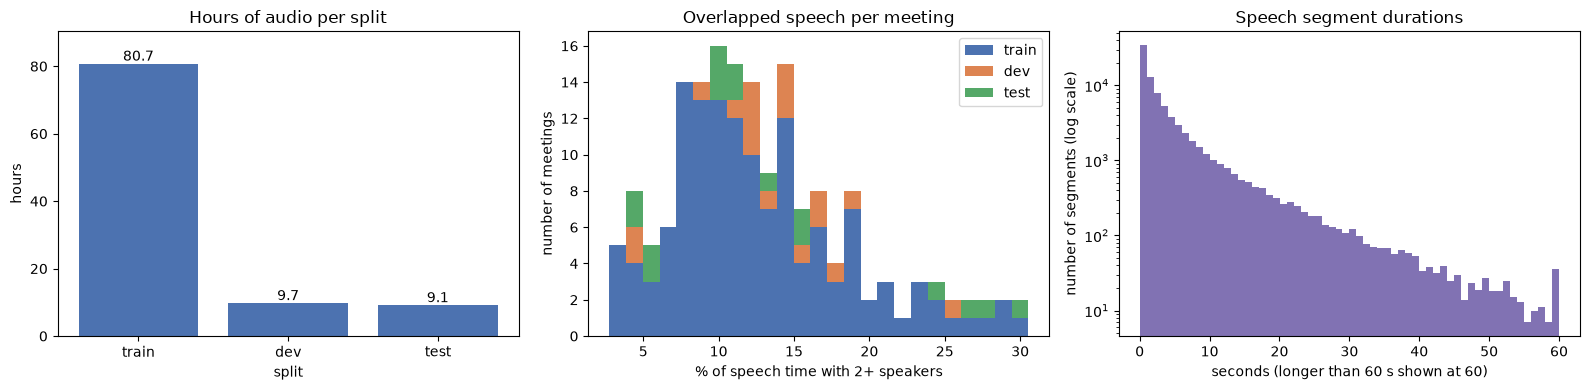

Saved: /workspace/results/figures/ami_dataset_overview.png


In [17]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 3, figsize=(16, 4))


# Chart 1- Hours of audio per split
bars = axes[0].bar(summary.index, summary["hours"], color="#4C72B0")
axes[0].bar_label(bars, fmt="%.1f")                       
axes[0].set_ylim(0, summary["hours"].max() * 1.12)         
axes[0].set_title("Hours of audio per split")
axes[0].set_xlabel("split")
axes[0].set_ylabel("hours")


# Chart 2- Overlapped speech per meeting 

overlap_by_split = []
for split in SPLITS:
    values = per_meeting.loc[per_meeting["split"] == split, "overlap_pct_of_speech"]
    overlap_by_split.append(values)

axes[1].hist(overlap_by_split, bins=25, stacked=True, label=SPLITS,
             color=["#4C72B0", "#DD8452", "#55A868"])      
axes[1].set_title("Overlapped speech per meeting")
axes[1].set_xlabel("% of speech time with 2+ speakers")
axes[1].set_ylabel("number of meetings")
axes[1].legend()


# Chart 3- How long each speech segment
durations = all_segments["duration_s"].clip(upper=60)
axes[2].hist(durations, bins=60, color="#8172B3")
axes[2].set_yscale("log")                                 
axes[2].set_title("Speech segment durations")
axes[2].set_xlabel("seconds (longer than 60 s shown at 60)")
axes[2].set_ylabel("number of segments (log scale)")


plt.tight_layout()                                        
plt.savefig(FIGURES / "ami_dataset_overview.png", dpi=150, bbox_inches="tight")   
plt.show()
print("Saved:", FIGURES / "ami_dataset_overview.png")

## Build the pyannote 2.1 environment


In [18]:
# Install conda 

import subprocess

CONDA     = WORK / "miniforge3"
CONDA_BIN = CONDA / "bin" / "conda"         

if not CONDA_BIN.exists():
    print("Installing Miniforge ...")
    !rm -rf {CONDA}
    !wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O /tmp/miniforge.sh
    !bash /tmp/miniforge.sh -b -p {CONDA}
else:
    print("Already installed - skipping.")

result = subprocess.run([str(CONDA_BIN), "--version"], capture_output=True, text=True, check=True)
conda_version = result.stdout.strip()
print("Working:", conda_version, "at", CONDA)
logging.info(f"conda: {conda_version}")

Installing Miniforge ...
PREFIX=/workspace/miniforge3
Unpacking bootstrapper...
Unpacking payload...
Extracting ca-certificates-2026.7.22-hbd8a1cb_0.conda
Extracting libgomp-16.2.0-he0feb66_4.conda
Extracting libzlib-1.3.2-h25fd6f3_3.conda
Extracting nlohmann_json-abi-3.12.0-h0f90c79_2.conda
Extracting pybind11-abi-11-hc364b38_1.conda
Extracting python_abi-3.14-9_cp314.conda
Extracting tzdata-2026c-h151e31d_0.conda
Extracting _openmp_mutex-4.5-20_gnu.conda
Extracting zstd-1.5.7-hb78ec9c_7.conda
Extracting ld_impl_linux-64-2.46.1-default_hbd61a6d_102.conda
Extracting libgcc-16.2.0-ha9f2e26_4.conda
Extracting bzip2-1.0.8-hda65f42_10.conda
Extracting c-ares-1.34.8-hebe6cf0_2.conda
Extracting keyutils-1.6.3-h7cc23a3_1.conda
Extracting libev-4.33-h280c20c_3.conda
Extracting libexpat-2.8.1-hecca717_1.conda
Extracting libffi-3.7.0-h81df57d_1.conda
Extracting libiconv-1.18-h0cb94f2_3.conda
Extracting liblzma-5.8.3-hb03c661_1.conda
Extracting libmpdec-4.0.0-hb03c661_2.conda
Extracting libstdcxx

In [19]:
# Create the Python 3.9 environment and install pinned packages (~5-10 min)

import subprocess

ENV_PYTHON = ENV / "bin" / "python"

# Create the environment 
if not ENV_PYTHON.exists():
    !rm -rf {ENV}
    !{CONDA}/bin/conda create -y -q -p {ENV} python=3.9
else:
    print("Environment already exists - skipping create.")

# PyTorch 1.13.1 built for CUDA 11.7
!{ENV}/bin/pip install -q torch==1.13.1 torchaudio==0.13.1 --index-url https://download.pytorch.org/whl/cu117

# pyannote 2.1.1 + helper versions that work with it + notebook support (ipykernel) + charts
!{ENV}/bin/pip install -q pyannote.audio==2.1.1 "numpy<1.24" "huggingface_hub<0.20" "setuptools<70" "typer[all]==0.9.0" pandas matplotlib ipykernel


# Test the environment 

# 1) Are any installed packages in conflict with each other?
check = subprocess.run([str(ENV_PYTHON), "-m", "pip", "check"], capture_output=True, text=True)
print("pip check:", check.stdout.strip())

# 2) Can we import pyannote and actually use the GPU?
test_code = """
import torch, pyannote.audio
print("python ok | torch", torch.__version__, "| pyannote", pyannote.audio.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(256, 256, device="cuda")
    print("GPU math test:", float((x @ x).sum()) is not None)
"""
test = subprocess.run([str(ENV_PYTHON), "-c", test_code], capture_output=True, text=True)
print(test.stdout)
if test.returncode != 0:
    print(test.stderr[-1500:])                     
    raise RuntimeError("Environment test failed - send this error to Claude.")



# Save the exact versions (reproducibility)

!{ENV}/bin/pip freeze > {WORK}/pyannote21_environment.txt
print("Exact versions saved to", WORK / "pyannote21_environment.txt")

Retrieving notices: ...working... done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: ...working... done

## Package Plan ##

  environment location: /workspace/envs/pyannote21

  added / updated specs:
    - python=3.9


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.10.19 |       hbd8a1cb_0         128 KB  conda-forge
    ld_impl_linux-64-2.46.1    |default_hbd61a6d_103         725 KB  conda-forge
    libexpat-2.8.5             |       hd2095e1_0          76 KB  conda-forge
    libgcc-16.2.0              |       ha9f2e26_7         1.0 MB  conda-forge
    libgomp-16.2.0             |       he0feb66_7         626 KB  conda-forge
    libnsl-2.0.1               |       hb9d3cd8_1          33 KB  conda-forge
    libsqlite-3.54.1           |     h0737f62_100         957 KB  conda-forge
    libuuid-2.42.4             |       hcfc3c73_0          34 KB  c

### Make the environment available as a notebook kernel

In [20]:
# Register the pyannote environment as a Jupyter kernel

!{ENV}/bin/python -m ipykernel install --user --name pyannote21 --display-name "Python (pyannote 2.1)"

# Check: the new kernel should appear in this list
!jupyter kernelspec list

Installed kernelspec pyannote21 in /root/.local/share/jupyter/kernels/pyannote21
Available kernels:
  pyannote21    /root/.local/share/jupyter/kernels/pyannote21
  python3       /usr/local/share/jupyter/kernels/python3


In [21]:
# Final check - versions and GPU 

info_file = LOG_DIR / f"environment_info_{RUN_ID}.txt"

!{ENV}/bin/python -c "import torch, pyannote.audio; print('torch', torch.__version__, '| pyannote.audio', pyannote.audio.__version__, '| GPU available:', torch.cuda.is_available())" > {info_file}
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv >> {info_file}

print(info_file.read_text())          
print("Saved to:", info_file)

torch 1.13.1+cu117 | pyannote.audio 2.1.1 | GPU available: True
name, memory.total [MiB], driver_version
NVIDIA A40, 46068 MiB, 595.91.07

Saved to: /workspace/logs/environment_info_20261020_205159.txt
